<a href="https://colab.research.google.com/github/Akash14-09/Machine_Learning/blob/main/Batch_Normalilzation_Implementation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [41]:
df = pd.read_csv('/content/Social_Network_Ads.csv')

In [42]:
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [43]:
df.rename(columns = {'Age' : 'X' , 'EstimatedSalary' : 'Y' , 'Purchased' : 'Z'} , inplace = True)

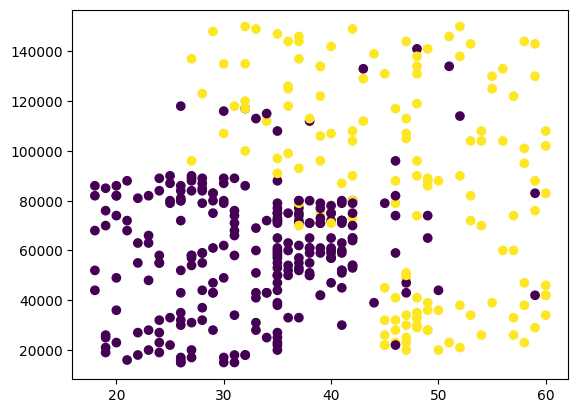

In [44]:
plt.scatter(df['X'] , df['Y'] , c= df['Z'] )

In [45]:
X = df.iloc[: , 0:2].values
y = df.iloc[: , -1].values

In [46]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Defining X using correct numeric columns
X_numeric = df.iloc[:, 2:4].values.astype('float32')
y_numeric = df.iloc[:, -1].values.astype('float32')

# Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X_numeric, y_numeric, test_size=0.2, random_state=42)

# Scale features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [47]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense
from tensorflow.keras.layers import BatchNormalization

In [48]:
model = Sequential()
model.add(Dense(2 , activation = 'relu', input_dim = 2))
model.add(Dense(2 , activation = 'relu'))
model.add(Dense(1 , activation = 'sigmoid'))

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 2)              │             6 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 2)              │             6 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15 (60.00 B)

 Trainable params: 15 (60.00 B)

 Non-trainable params: 0 (0.00 B)

In [49]:
#creating model without applying batch normalization
model.compile(loss = 'binary_crossentropy' , optimizer = 'adam' , metrics = ['accuracy'])

In [50]:
# Redefining X to use the actual numerical features 'X' (Age) and 'Y' (EstimatedSalary)
# columns are: ['User ID', 'Gender', 'X', 'Y', 'Z']
X = df.iloc[:, 2:4].values.astype('float32')
y = df.iloc[:, -1].values.astype('float32')

history1 = model.fit(X, y, epochs=200, validation_split=0.2)

Epoch 1/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.7125 - loss: 0.6923 - val_accuracy: 0.3625 - val_loss: 0.6944
Epoch 2/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7125 - loss: 0.6904 - val_accuracy: 0.3625 - val_loss: 0.6957
Epoch 3/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7125 - loss: 0.6885 - val_accuracy: 0.3625 - val_loss: 0.6971
Epoch 4/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7125 - loss: 0.6866 - val_accuracy: 0.3625 - val_loss: 0.6984
Epoch 5/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7125 - loss: 0.6846 - val_accuracy: 0.3625 - val_loss: 0.6997
Epoch 6/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7125 - loss: 0.6827 - val_accuracy: 0.3625 - val_loss: 0.7010
Epoch 7/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7125 - loss: 0.6810 - val_accuracy: 0.3625 - val_loss: 0.7024
Epoch 8/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7125 - loss: 0.6793 - val_accuracy: 0.

In [51]:
#now applying batch normalization
model = Sequential()
model.add(Dense(2 , activation = 'relu', input_dim = 2))
model.add(BatchNormalization())
model.add(Dense(2 , activation = 'relu'))
model.add(BatchNormalization())
model.add(Dense(1 , activation = 'sigmoid'))

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 2)              │             6 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 2)              │             8 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 2)              │             6 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 2)              │             8 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31 (124.00 B)

 Trainable params: 23 (92.00 B)

 Non-trainable params: 8 (32.00 B)

In [52]:
model.compile(loss = 'binary_crossentropy' , optimizer = 'adam' , metrics = ['accuracy'])

In [53]:
history2 = model.fit(X, y, epochs=200, validation_split=0.2)

Epoch 1/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 51ms/step - accuracy: 0.7125 - loss: 0.6909 - val_accuracy: 0.3625 - val_loss: 0.6966
Epoch 2/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.7125 - loss: 0.6859 - val_accuracy: 0.3625 - val_loss: 0.7001
Epoch 3/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.7125 - loss: 0.6809 - val_accuracy: 0.3625 - val_loss: 0.7039
Epoch 4/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.7125 - loss: 0.6763 - val_accuracy: 0.3625 - val_loss: 0.7080
Epoch 5/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.7125 - loss: 0.6713 - val_accuracy: 0.3625 - val_loss: 0.7120
Epoch 6/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7125 - loss: 0.6667 - val_accuracy: 0.3625 - val_loss: 0.7163
Epoch 7/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7125 - loss: 0.6622 - val_accuracy: 0.3625 - val_loss: 0.7208
Epoch 8/200
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7125 - loss: 0.6581 - val_accuracy: 0.

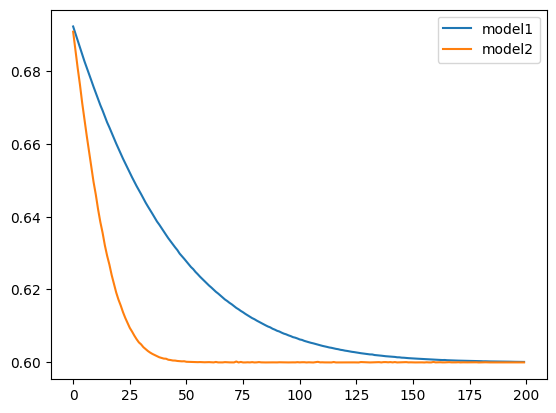

In [54]:
plt.plot(history1.history['loss'] , label = 'model1' )
plt.plot(history2.history['loss'] , label = 'model2')
plt.legend()

Here in the above graph we can see with the help of batch normalization the model is showing the faster convergence

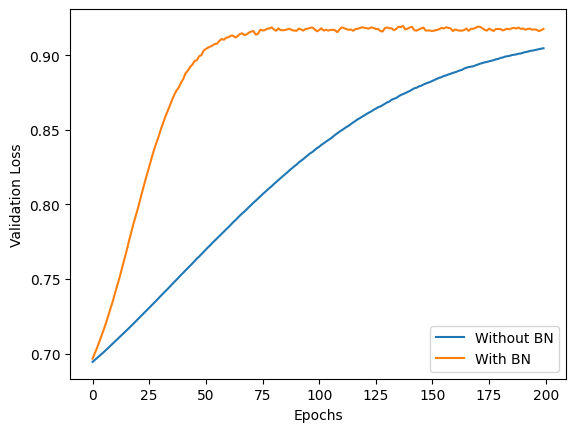

In [56]:
plt.plot(history1.history['val_loss'], label='Without BN')
plt.plot(history2.history['val_loss'], label='With BN')
plt.xlabel('Epochs')
plt.ylabel('Validation Loss')
plt.legend()
plt.show()